# Tugas Proyek Machine Learning
**Tema:** SDGs 13: Aksi Iklim  
**Kelompok:** [Kelompok 37 : Crop Yield Forecasting Under Climate Stress]

## Definisi Masalah
Kami menganalisis dampak anomali iklim ekstrem, khususnya suhu dan curah hujan, serta ketersediaan lahan terhadap ketahanan pangan, dengan fokus pada produksi padi di beberapa kabupaten penghasil padi di Jawa Barat menggunakan statistik pertanian resmi.

## Tujuan
Membangun model Regresi Linear Berganda *dari nol* dengan regularisasi L2 opsional. Model ini digunakan untuk memprediksi produksi padi tahunan dalam satuan ribu ton berdasarkan data iklim historis dan luas panen, lalu dimanfaatkan untuk mensimulasikan skenario ketahanan pangan pada kondisi cuaca ekstrem yang relevan dengan SDG 13.

## Detail Dataset
* **Jenis Masalah:** Regresi
* **Metode:** Regresi Linear Berganda dari nol dengan Gradient Descent, serta regularisasi L2 opsional yang diuji saat grid search
* **Variabel Target (Y):** Produksi padi tahunan (ton, diskalakan menjadi ribu ton). Sumber: Open Data Jabar dan BPS Jawa Barat.
* **Fitur (X):** Suhu rata-rata (degC), total curah hujan (mm), dan luas panen (hektare).
* **Periode Waktu:** 2013 - 2024

## Sumber Data Resmi
* **Iklim:** Open-Meteo Archive API, yaitu data historis harian suhu dan curah hujan yang kemudian diagregasi menjadi fitur tahunan. https://archive-api.open-meteo.com/
* **Produksi (ekspor lokal 2013-2025):** Tabel Open Data Jabar dan BPS Jawa Barat tentang produksi padi menurut kabupaten/kota. https://opendata.jabarprov.go.id/en/dataset/produksi-padi-berdasarkan-kabupatenkota-di-jawa-barat dan https://jabar.bps.go.id/id/statistics-table/3/ZDNaak0yODBUVTlGYW5sa2REUkVUVVY1YVZkbmR6MDkjMw==/produksi-padi-sup-1--sup--dan-beras-menurut-kabupaten-kota-di-provinsi-jawa-barat--2023.html?year=2025
* **Luas Panen (ekspor lokal 2013-2025):** Data luas panen padi Open Data Jabar yang digabung dengan tabel BPS Jawa Barat tentang luas panen, produktivitas, dan produksi padi. https://opendata.jabarprov.go.id/id/dataset/luas-panen-padi-berdasarkan-komoditi-di-jawa-barat dan https://jabar.bps.go.id/id/statistics-table/3/WmpaNk1YbGFjR0pOUjBKYWFIQlBSU3MwVHpOVWR6MDkjMw==/luas-panen--produktivitas--dan-produksi-padi-menurut-kabupaten-kota-di-provinsi-jawa-barat--2020.html?year=2020

## Catatan Reproduksibilitas
Notebook ini disusun agar data iklim diambil langsung dari Open-Meteo Archive API, sedangkan data produksi dan luas panen dibaca dari CSV resmi pada repo GitHub `amantajatii/dataset-padi-official` dengan fallback ke folder lokal `data_official/`. Dengan pendekatan ini, fitur iklim selalu dapat diperbarui dari sumber API, sementara statistik pertanian tetap konsisten dan mudah direproduksi.

## Desain Evaluasi
* **Periode Training:** 2013-2021
* **Periode Validasi:** 2022-2023
* **Periode Test:** 2024
* **Metrik:** MSE, RMSE, MAE, dan R-Squared


## 1. Memuat dan Menyiapkan Data (Data Resmi + Fetch Iklim API)

### Langkah 1.1: Strategi Pemanggilan Data dan Sumber Iklim
Dalam notebook ini, data iklim diambil langsung dari Open-Meteo Archive API, kemudian diagregasi dari data harian menjadi fitur tahunan. Sementara itu, statistik pertanian resmi tetap dibaca dari file CSV pada repo GitHub publik atau fallback ke folder lokal `data_official/`.

1. **Data Iklim (X):** Diambil langsung dari Open-Meteo Archive API pada level harian, lalu diagregasi menjadi rata-rata suhu tahunan dan total curah hujan tahunan per kabupaten.
2. **Produksi Padi (Y) dan Luas Panen (X):** Dimuat dari file CSV pada folder `data_official/` di repo GitHub publik.

**Catatan dokumentasi:**
Notebook akan memanggil Open-Meteo API secara langsung untuk data iklim. Untuk data produksi dan luas panen, notebook mencoba membaca CSV dari URL raw GitHub dengan fallback ke folder lokal `data_official/` jika akses internet bermasalah atau repo tidak dapat dijangkau.


In [ ]:
from io import StringIO
import pandas as pd
import numpy as np
import requests
import time
import itertools
from IPython.display import display
import matplotlib.pyplot as plt


In [ ]:
# 1A. FETCH CLIMATE DATA DIRECTLY FROM OPEN-METEO API
from pathlib import Path

START_YEAR = 2013
END_YEAR = 2024

lokasi = {
    'Bandung': {'lat': -7.0296, 'lon': 107.5187},
    'Bandung Barat': {'lat': -6.8126, 'lon': 107.4741},
    'Bekasi': {'lat': -6.2615, 'lon': 107.1536},
    'Bogor': {'lat': -6.4852, 'lon': 106.8540},
    'Ciamis': {'lat': -7.3257, 'lon': 108.3534},
    'Cianjur': {'lat': -6.8173, 'lon': 107.1427},
    'Cirebon': {'lat': -6.7063, 'lon': 108.5570},
    'Garut': {'lat': -7.2279, 'lon': 107.9087},
    'Indramayu': {'lat': -6.3275, 'lon': 108.3249},
    'Karawang': {'lat': -6.3227, 'lon': 107.3066},
    'Kuningan': {'lat': -6.9758, 'lon': 108.4832},
    'Majalengka': {'lat': -6.8369, 'lon': 108.2270},
    'Pangandaran': {'lat': -7.7018, 'lon': 108.4965},
    'Purwakarta': {'lat': -6.5569, 'lon': 107.4430},
    'Subang': {'lat': -6.5686, 'lon': 107.7644},
    'Sukabumi': {'lat': -6.9833, 'lon': 106.5508},
    'Sumedang': {'lat': -6.8576, 'lon': 107.9228},
    'Tasikmalaya': {'lat': -7.3274, 'lon': 108.2141}
}
target_kab = list(lokasi.keys())
print(f"Menggunakan {len(target_kab)} kabupaten untuk analisis: {', '.join(target_kab)}")

PROJECT_DIR = Path.cwd()
LOCAL_DATA_DIR = PROJECT_DIR / 'data_official'
CACHE_DATA_DIR = PROJECT_DIR / '.gacor_cache'
CACHE_DATA_DIR.mkdir(exist_ok=True)
DATA_FILES = {
    'produksi': 'produksi_resmi.csv',
    'luas': 'luas_panen_resmi.csv'
}
RAW_BASE_URLS = [
    'https://raw.githubusercontent.com/amantajatii/dataset-padi-official/main/data_official',
]
http_session = requests.Session()

def fetch_openmeteo_yearly(start_year, end_year, lokasi_map, timezone='Asia/Jakarta', max_retries=5, base_sleep=5, use_existing_cache=True, force_refresh=False):
    print('<Fetching data iklim langsung dari Open-Meteo API>')
    kumpulan_data = []

    for idx, (kab, coords) in enumerate(lokasi_map.items(), start=1):
        cache_path = CACHE_DATA_DIR / f"openmeteo_{kab.lower().replace(' ', '_')}_{start_year}_{end_year}.csv"
        if use_existing_cache and cache_path.exists() and not force_refresh:
            print(f"[{idx}/{len(lokasi_map)}] Menggunakan cache API yang sudah ada untuk {kab}: {cache_path.name}")
            kumpulan_data.append(pd.read_csv(cache_path))
            continue

        url = (
            'https://archive-api.open-meteo.com/v1/archive'
            f"?latitude={coords['lat']}"
            f"&longitude={coords['lon']}"
            f"&start_date={start_year}-01-01"
            f"&end_date={end_year}-12-31"
            '&daily=temperature_2m_mean,precipitation_sum'
            f'&timezone={timezone}'
        )

        print(f"[{idx}/{len(lokasi_map)}] Mengambil data iklim {kab} dari API...")
        last_error = None

        for attempt in range(1, max_retries + 1):
            try:
                response = http_session.get(url, timeout=60)
                response.raise_for_status()
                payload = response.json()

                if 'daily' not in payload:
                    raise ValueError(f"Respons Open-Meteo tidak memuat data harian untuk {kab}: {payload}")

                df_harian = pd.DataFrame(payload['daily'])
                if df_harian.empty:
                    raise ValueError(f'Data harian Open-Meteo kosong untuk {kab}')

                df_harian['time'] = pd.to_datetime(df_harian['time'])
                df_harian['Tahun'] = df_harian['time'].dt.year
                df_tahunan = (
                    df_harian.groupby('Tahun', as_index=False)
                    .agg(
                        Suhu_Rata_C=('temperature_2m_mean', 'mean'),
                        Curah_Hujan_mm=('precipitation_sum', 'sum')
                    )
                )

                df_tahunan['Kabupaten'] = kab
                df_tahunan[['Suhu_Rata_C', 'Curah_Hujan_mm']] = df_tahunan[['Suhu_Rata_C', 'Curah_Hujan_mm']].round(2)
                df_tahunan.to_csv(cache_path, index=False)
                kumpulan_data.append(df_tahunan)
                time.sleep(1.5)
                break
            except requests.HTTPError as exc:
                last_error = exc
                status_code = exc.response.status_code if exc.response is not None else None
                if status_code == 429 and attempt < max_retries:
                    wait_seconds = base_sleep * attempt
                    print(f"   Rate limit Open-Meteo untuk {kab}. Retry {attempt}/{max_retries} dalam {wait_seconds} detik...")
                    time.sleep(wait_seconds)
                    continue
                if cache_path.exists():
                    print(f"   API gagal untuk {kab}. Menggunakan cache API yang sudah tersimpan: {cache_path.name}")
                    kumpulan_data.append(pd.read_csv(cache_path))
                    break
                raise
            except Exception as exc:
                last_error = exc
                if cache_path.exists():
                    print(f"   Gagal mengambil data {kab}. Menggunakan cache API yang sudah tersimpan: {cache_path.name}")
                    kumpulan_data.append(pd.read_csv(cache_path))
                    break
                raise
        else:
            if cache_path.exists():
                print(f"   Semua retry habis untuk {kab}. Menggunakan cache API yang sudah tersimpan: {cache_path.name}")
                kumpulan_data.append(pd.read_csv(cache_path))
            else:
                raise RuntimeError(f'Gagal mengambil data Open-Meteo untuk {kab}') from last_error

    df_iklim_api = pd.concat(kumpulan_data, ignore_index=True)
    return df_iklim_api

def read_csv_from_github_or_local(filename):
    errors = []
    cache_path = CACHE_DATA_DIR / filename

    for base_url in RAW_BASE_URLS:
        csv_url = f'{base_url}/{filename}'
        try:
            response = http_session.get(csv_url, timeout=20)
            response.raise_for_status()
            cache_path.write_text(response.text, encoding='utf-8')
            df = pd.read_csv(StringIO(response.text))
            print(f'Dataset berhasil dimuat dari GitHub: {csv_url}')
            return df, csv_url
        except Exception as exc:
            errors.append(f'{csv_url} -> {exc}')

    if cache_path.exists():
        print(f'Fallback ke cache runtime: {cache_path}')
        return pd.read_csv(cache_path), str(cache_path)

    local_path = LOCAL_DATA_DIR / filename
    if local_path.exists():
        print(f'Fallback ke file lokal: {local_path}')
        return pd.read_csv(local_path), str(local_path)

    error_message = '\n'.join(f'- {item}' for item in errors)
    raise FileNotFoundError(
        f'Gagal memuat {filename} dari GitHub maupun file lokal. Detail percobaan:\n{error_message}'
    )

df_iklim = fetch_openmeteo_yearly(START_YEAR, END_YEAR, lokasi)
iklim_source = 'Open-Meteo Archive API'
df_iklim = df_iklim[['Tahun', 'Suhu_Rata_C', 'Curah_Hujan_mm', 'Kabupaten']].copy()
df_iklim['Tahun'] = pd.to_numeric(df_iklim['Tahun'], errors='coerce').astype('Int64')
df_iklim['Kabupaten'] = df_iklim['Kabupaten'].astype(str).str.strip().str.title()
df_iklim['Suhu_Rata_C'] = pd.to_numeric(df_iklim['Suhu_Rata_C'], errors='coerce')
df_iklim['Curah_Hujan_mm'] = pd.to_numeric(df_iklim['Curah_Hujan_mm'], errors='coerce')
df_iklim = df_iklim.dropna(subset=['Tahun', 'Kabupaten', 'Suhu_Rata_C', 'Curah_Hujan_mm'])
df_iklim['Tahun'] = df_iklim['Tahun'].astype(int)
df_iklim = df_iklim[(df_iklim['Tahun'] >= START_YEAR) & (df_iklim['Tahun'] <= END_YEAR)]
df_iklim = df_iklim[df_iklim['Kabupaten'].isin(target_kab)].copy()

print(f"Data iklim berhasil diambil: {len(df_iklim)} baris dari {iklim_source}")

# 1B. LOAD OFFICIAL AGRICULTURAL STATISTICS (LOCAL EXPORTS)
def normalize_kabupaten(name):
    value = str(name).strip().upper()
    if value.startswith('KABUPATEN '):
        return value.replace('KABUPATEN ', '', 1).title()
    if value.startswith('KOTA '):
        return 'Kota ' + value.replace('KOTA ', '', 1).title()
    return value.title()

df_produksi, produksi_source = read_csv_from_github_or_local(DATA_FILES['produksi'])
df_luas, luas_source = read_csv_from_github_or_local(DATA_FILES['luas'])

df_produksi = df_produksi[['Tahun', 'Kabupaten', 'Produksi']].copy()
df_luas = df_luas[['Tahun', 'Kabupaten', 'Luas_Panen_Ha']].copy()

for df_temp in [df_produksi, df_luas]:
    df_temp['Tahun'] = pd.to_numeric(df_temp['Tahun'], errors='coerce').astype('Int64')
    df_temp['Kabupaten'] = df_temp['Kabupaten'].map(normalize_kabupaten)

df_produksi['Produksi'] = pd.to_numeric(df_produksi['Produksi'], errors='coerce')
df_luas['Luas_Panen_Ha'] = pd.to_numeric(df_luas['Luas_Panen_Ha'], errors='coerce')

df_produksi = df_produksi.dropna(subset=['Tahun', 'Kabupaten', 'Produksi'])
df_luas = df_luas.dropna(subset=['Tahun', 'Kabupaten', 'Luas_Panen_Ha'])

df_produksi['Tahun'] = df_produksi['Tahun'].astype(int)
df_luas['Tahun'] = df_luas['Tahun'].astype(int)

df_produksi = df_produksi[(df_produksi['Tahun'] >= START_YEAR) & (df_produksi['Tahun'] <= END_YEAR)]
df_luas = df_luas[(df_luas['Tahun'] >= START_YEAR) & (df_luas['Tahun'] <= END_YEAR)]

df_produksi = df_produksi[df_produksi['Kabupaten'].isin(target_kab)].copy()
df_luas = df_luas[df_luas['Kabupaten'].isin(target_kab)].copy()

print("\nData berhasil dimuat. Berikut adalah cuplikan dataset iklim:")
print(f"Sumber produksi: {produksi_source}")
print(f"Sumber luas panen: {luas_source}")
display(df_iklim.head(len(target_kab) * 3))


Menggunakan 18 kabupaten untuk analisis: Bandung, Bandung Barat, Bekasi, Bogor, Ciamis, Cianjur, Cirebon, Garut, Indramayu, Karawang, Kuningan, Majalengka, Pangandaran, Purwakarta, Subang, Sukabumi, Sumedang, Tasikmalaya
<Fetching data iklim langsung dari Open-Meteo API>
[1/18] Mengambil data iklim Bandung dari API...
[2/18] Mengambil data iklim Bandung Barat dari API...
[3/18] Mengambil data iklim Bekasi dari API...
[4/18] Mengambil data iklim Bogor dari API...
[5/18] Mengambil data iklim Ciamis dari API...
[6/18] Mengambil data iklim Cianjur dari API...
[7/18] Mengambil data iklim Cirebon dari API...
[8/18] Mengambil data iklim Garut dari API...
[9/18] Mengambil data iklim Indramayu dari API...
[10/18] Mengambil data iklim Karawang dari API...
[11/18] Mengambil data iklim Kuningan dari API...
   Rate limit Open-Meteo untuk Kuningan. Retry 1/5 dalam 5 detik...
   Rate limit Open-Meteo untuk Kuningan. Retry 2/5 dalam 10 detik...
[12/18] Mengambil data iklim Majalengka dari API...
[13/1

,Tahun,Suhu_Rata_C,Curah_Hujan_mm,Kabupaten
0,2013,22.88,3851.9,Bandung
1,2014,23.03,3412.3,Bandung
2,2015,23.42,3107.9,Bandung
3,2016,23.17,4727.8,Bandung
4,2017,22.60,1891.7,Bandung
5,2018,22.63,1720.8,Bandung
6,2019,22.89,1740.7,Bandung
7,2020,22.78,2573.1,Bandung
8,2021,22.38,2919.0,Bandung
9,2022,22.28,2379.1,Bandung


### Langkah 1.2: Penggabungan Data dan Prapemrosesan
Setelah seluruh data berhasil dimuat, data digabung secara presisi menggunakan `Tahun` dan `Kabupaten` sebagai kunci utama. Pada tahap ini juga dilakukan pembersihan tipe data, penghapusan nilai hilang yang kritis, penskalaan target, dan one-hot encoding untuk variabel wilayah.


In [ ]:
# 2A. DATA MERGING (PENGGABUNGAN PRESISI)
# Konversi tipe data agar tidak terjadi Bug NaN
for df_temp in [df_produksi, df_iklim, df_luas]:
    df_temp['Tahun'] = df_temp['Tahun'].astype(int)
    df_temp['Kabupaten'] = df_temp['Kabupaten'].astype(str).str.strip().str.title()

df_full = df_produksi.merge(df_iklim, on=['Tahun', 'Kabupaten']).merge(df_luas, on=['Tahun', 'Kabupaten'], how='left')
df_full = df_full.dropna(subset=['Produksi'])

missing_luas = df_full['Luas_Panen_Ha'].isna().sum()
if missing_luas > 0:
    print(f"Peringatan: {missing_luas} baris dibuang karena data Luas_Panen_Ha belum tersedia. Lengkapi file resmi lokal untuk periode {START_YEAR}-{END_YEAR} agar lebih banyak kabupaten bisa dipakai.")
df_full = df_full.dropna(subset=['Luas_Panen_Ha']).reset_index(drop=True)

# 2B. TARGET SCALING & ONE-HOT ENCODING
X_df = df_full[['Curah_Hujan_mm', 'Suhu_Rata_C', 'Luas_Panen_Ha', 'Kabupaten']].copy()
y_df = df_full['Produksi'].copy() / 1000  # Skala diturunkan ke Ribu Ton

X_df = pd.get_dummies(X_df, columns=['Kabupaten'], drop_first=True)

print(" Merging & Imputasi SELESAI!")
display(X_df.head(3))

 Merging & Imputasi SELESAI!


,Curah_Hujan_mm,Suhu_Rata_C,Luas_Panen_Ha,Kabupaten_Bandung Barat,Kabupaten_Bekasi,Kabupaten_Bogor,Kabupaten_Ciamis,Kabupaten_Cianjur,Kabupaten_Cirebon,Kabupaten_Garut,Kabupaten_Indramayu,Kabupaten_Karawang,Kabupaten_Kuningan,Kabupaten_Majalengka,Kabupaten_Pangandaran,Kabupaten_Purwakarta,Kabupaten_Subang,Kabupaten_Sukabumi,Kabupaten_Sumedang,Kabupaten_Tasikmalaya
0,3343.8,25.38,93228.0,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,3997.1,26.07,149180.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
2,2912.7,23.98,153178.0,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False


### Langkah 1.3: Split Kronologis dan Standardisasi (Z-Score)
Kami membangun splitter kronologis dan standardizer sendiri menggunakan NumPy.
* Karena proyek ini memprediksi produksi padi berdasarkan urutan waktu, dataset diurutkan berdasarkan tahun dan menggunakan **split kronologis** alih-alih pengacakan acak.
* Data **2013-2021** digunakan untuk pelatihan, **2022-2023** untuk validasi saat hyperparameter tuning, dan **2024** sebagai data pengujian akhir yang benar-benar belum pernah dilihat model.
* **Normalisasi Z-Score** diterapkan pada fitur numerik (`Curah_Hujan_mm`, `Suhu_Rata_C`, `Luas_Panen_Ha`) menggunakan mean dan standar deviasi dari data pelatihan saja agar tidak terjadi kebocoran data.


In [ ]:
# 3. SPLIT KRONOLOGIS DAN STANDARDISASI
df_model = X_df.copy()
df_model['Target_Produksi'] = y_df.values
df_model['Tahun'] = df_full['Tahun'].values
df_model = df_model.sort_values(['Tahun']).reset_index(drop=True)

train_mask = df_model['Tahun'] <= 2021
val_mask = (df_model['Tahun'] >= 2022) & (df_model['Tahun'] <= 2023)
pengujian_mask = df_model['Tahun'] >= 2024

feature_cols = X_df.columns.tolist()
num_cols = ['Curah_Hujan_mm', 'Suhu_Rata_C', 'Luas_Panen_Ha']

def prepare_feature_frame(frame):
    prepared = frame.copy()
    prepared[num_cols] = prepared[num_cols].astype(float)
    return prepared

def fit_standardizer(frame):
    mean = frame[num_cols].mean(axis=0)
    std = frame[num_cols].std(axis=0).replace(0, 1e-8)
    return mean, std

def apply_standardizer(frame, mean, std):
    scaled = prepare_feature_frame(frame)
    scaled.loc[:, num_cols] = (scaled[num_cols] - mean) / std
    return scaled

X_train_raw = prepare_feature_frame(df_model.loc[train_mask, feature_cols])
y_train = df_model.loc[train_mask, 'Target_Produksi'].copy()
X_val_raw = prepare_feature_frame(df_model.loc[val_mask, feature_cols])
y_val = df_model.loc[val_mask, 'Target_Produksi'].copy()
X_pengujian_raw = prepare_feature_frame(df_model.loc[pengujian_mask, feature_cols])
y_pengujian = df_model.loc[pengujian_mask, 'Target_Produksi'].copy()

# Standardisasi untuk fase tuning hanya memakai statistik data latih.
X_mean, X_std = fit_standardizer(X_train_raw)
X_train = apply_standardizer(X_train_raw, X_mean, X_std)
X_val = apply_standardizer(X_val_raw, X_mean, X_std)
X_pengujian = apply_standardizer(X_pengujian_raw, X_mean, X_std)

print("Split kronologis dan normalisasi SELESAI!")
print("Dimensi Data Latih     :", X_train.shape)
print("Dimensi Data Validasi  :", X_val.shape)
print("Dimensi Data Uji       :", X_pengujian.shape)

Split kronologis dan normalisasi SELESAI!
Dimensi Data Latih     : (161, 20)
Dimensi Data Validasi  : (36, 20)
Dimensi Data Uji       : (18, 20)


## 2. Implementasi Regresi Linear Kustom dengan L2 Opsional dari Nol

### Subtugas:
Membangun arsitektur Object-Oriented Programming (OOP) untuk `RidgeLinearRegression`. Bagian ini mencakup inisialisasi, algoritma gradient descent kustom dengan penalti L2 opsional, fungsi prediksi, dan kalkulator R-squared manual.

**Alasan pemilihan desain:**
Untuk menjaga efisiensi komputasi, transpose matriks dan pembagian skalar statis disimpan di luar loop pelatihan. Saat $\lambda > 0$, model berperan sebagai Ridge Regression; saat $\lambda = 0$, model menjadi regresi linear berganda biasa. Penjelasan ini membuat implementasi tetap jujur terhadap hyperparameter yang akhirnya terpilih.


In [ ]:
class RidgeLinearRegression:
    def __init__(self, learning_rate=0.01, epochs=5000, lambda_param=0.1):
        self.lr = learning_rate
        self.epochs = epochs
        self.lambda_param = lambda_param
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        X_arr = np.array(X, dtype=float)
        y_arr = np.array(y, dtype=float).flatten()
        n_samples, n_features = X_arr.shape

        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        # Algorithmic Optimization (Caching)
        X_T = X_arr.T
        m_inv_2 = 2 / n_samples
        lambda_2 = 2 * self.lambda_param

        for _ in range(self.epochs):
            y_pred = np.dot(X_arr, self.weights) + self.bias
            error = y_pred - y_arr

            # Update Gradien O(1) Perkalian Matrix
            dw = m_inv_2 * np.dot(X_T, error) + (lambda_2 * self.weights)
            db = m_inv_2 * np.sum(error)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            self.loss_history.append((1 / n_samples) * np.sum(error ** 2))

    def predict(self, X):
        return np.dot(np.array(X, dtype=float), self.weights) + self.bias

def r2_score_manual(y_true, y_pred):
    y_t = np.array(y_true)
    sst = np.sum((y_t - np.mean(y_t)) ** 2)
    ssr = np.sum((y_t - np.array(y_pred)) ** 2)
    return 1 - (ssr / sst) if sst != 0 else 0

print("Arsitektur OOP Ridge Regression Siap!")

Arsitektur OOP Ridge Regression Siap!


## 3. Tuning Hyperparameter Sistematis (Grid Search)

### Subtugas:
Mengimplementasikan algoritma Grid Search kustom menggunakan `itertools` untuk menguji kombinasi `learning_rate`, `epochs`, dan penalti L2 (`lambda`) secara sistematis, lalu memilih model dengan Mean Squared Error (MSE) validasi terendah.

**Catatan interpretasi:**
Jika model terbaik diperoleh saat `lambda = 0.0`, maka model final harus dijelaskan sebagai regresi linear berganda biasa, bukan Ridge aktif.


In [ ]:
print("< MEMULAI GRID SEARCH TUNING HYPERPARAMETER >")

learning_rates = [0.001, 0.01, 0.05]
epochs_list = [2000, 5000, 10000]
lambdas = [0.0, 0.1, 1.0, 5.0]

best_val_mse = float('inf')
# Jaring Pengaman: Nilai Default (Failsafe) agar tidak crash jika terjadi hal buruk
best_params = {'lr': 0.01, 'epochs': 5000, 'lambda_param': 0.1}

kombinasi = list(itertools.product(learning_rates, epochs_list, lambdas))

for lr, ep, lam in kombinasi:
    temp_model = RidgeLinearRegression(learning_rate=lr, epochs=ep, lambda_param=lam)
    temp_model.fit(X_train, y_train)

    preds = temp_model.predict(X_val)
    current_mse = np.mean((y_val.values - preds) ** 2)

    # Proteksi tambahan: Abaikan nilai jika hasilnya NaN
    if current_mse < best_val_mse and not np.isnan(current_mse):
        best_val_mse = current_mse
        best_params = {'lr': lr, 'epochs': ep, 'lambda_param': lam}

print(f"Parameter terbaik ditemukan:")
print(f"LR: {best_params['lr']} | Epochs: {best_params['epochs']} | L2(λ): {best_params['lambda_param']}")
print(f"MSE validasi terbaik: {best_val_mse:.2f}")

< MEMULAI GRID SEARCH TUNING HYPERPARAMETER >
Parameter terbaik ditemukan:
LR: 0.05 | Epochs: 10000 | L2(λ): 0.0
MSE validasi terbaik: 2295.18


## 4. Melatih Model Final dan Mengevaluasi Performa

### Subtugas:
Melatih model final menggunakan gabungan data pelatihan dan validasi dengan parameter terbaik, lalu mengevaluasi kemampuan generalisasinya pada data pengujian kronologis yang belum pernah dilihat sebelumnya.


In [ ]:
print("< Melatih model final >")

final_model = RidgeLinearRegression(
    learning_rate=best_params['lr'],
    epochs=best_params['epochs'],
    lambda_param=best_params['lambda_param']
)

# Refit scaler pada gabungan train+validation agar model final konsisten.
X_train_final_raw = pd.concat([X_train_raw, X_val_raw], axis=0).reset_index(drop=True)
y_train_final = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)
X_mean_final, X_std_final = fit_standardizer(X_train_final_raw)
X_train_final = apply_standardizer(X_train_final_raw, X_mean_final, X_std_final)
X_pengujian_final = apply_standardizer(X_pengujian_raw, X_mean_final, X_std_final)
final_model.fit(X_train_final, y_train_final)

# Prediksi & Evaluasi
y_pred_pengujian = final_model.predict(X_pengujian_final)
y_pengujian_np = np.array(y_pengujian)
residuals = y_pengujian_np - y_pred_pengujian
pengujian_mse = np.mean(residuals**2)
pengujian_rmse = np.sqrt(pengujian_mse)
pengujian_mae = np.mean(np.abs(residuals))
pengujian_r2 = r2_score_manual(y_pengujian_np, y_pred_pengujian)
selected_model_name = "Regresi Linear Berganda" if best_params['lambda_param'] == 0.0 else "Ridge Regression"

print(f"\n< METRIK EVALUASI DATA TEST (Data Kronologis Tak Terlihat: {END_YEAR}) >")
print(f"Model Terpilih : {selected_model_name}")
print(f"MSE  : {pengujian_mse:.2f}")
print(f"RMSE : {pengujian_rmse:.2f}")
print(f"MAE  : {pengujian_mae:.2f}")
print(f"R2   : {pengujian_r2:.4f}")
print(f"\nBobot akhir yang dipelajari (W): {final_model.weights}")
print(f"Bias akhir (b)           : {final_model.bias:.2f}")

< Melatih model final >

< METRIK EVALUASI DATA TEST (Data Kronologis Tak Terlihat: 2024) >
Model Terpilih : Regresi Linear Berganda
MSE  : 2234.07
RMSE : 47.27
MAE  : 37.48
R2   : 0.9799

Bobot akhir yang dipelajari (W): [ 31.61867004  15.11868877 267.90081604 -48.92070529  10.65564868
 -18.58466216 -22.11715511  29.6801875   41.25826945  21.9371493
 252.75565047 175.30819209 -10.99532572  52.04985787 -46.52451417
 -50.71739697 123.44410326 -46.66897786 -28.36843602  25.05210263]
Bias akhir (b)           : 552.73


## 5. Visualisasi Hasil dan Analisis Residual

### Subtugas:
Membuat tiga visualisasi penting:
#####(1) Kurva loss Gradient Descent
#####(2) Scatter plot nilai aktual vs prediksi produksi
#####(3) Plot residual error untuk menganalisis variasi error dan potensi bias.



< Berikut adalah Hasil Visualisasi Data >



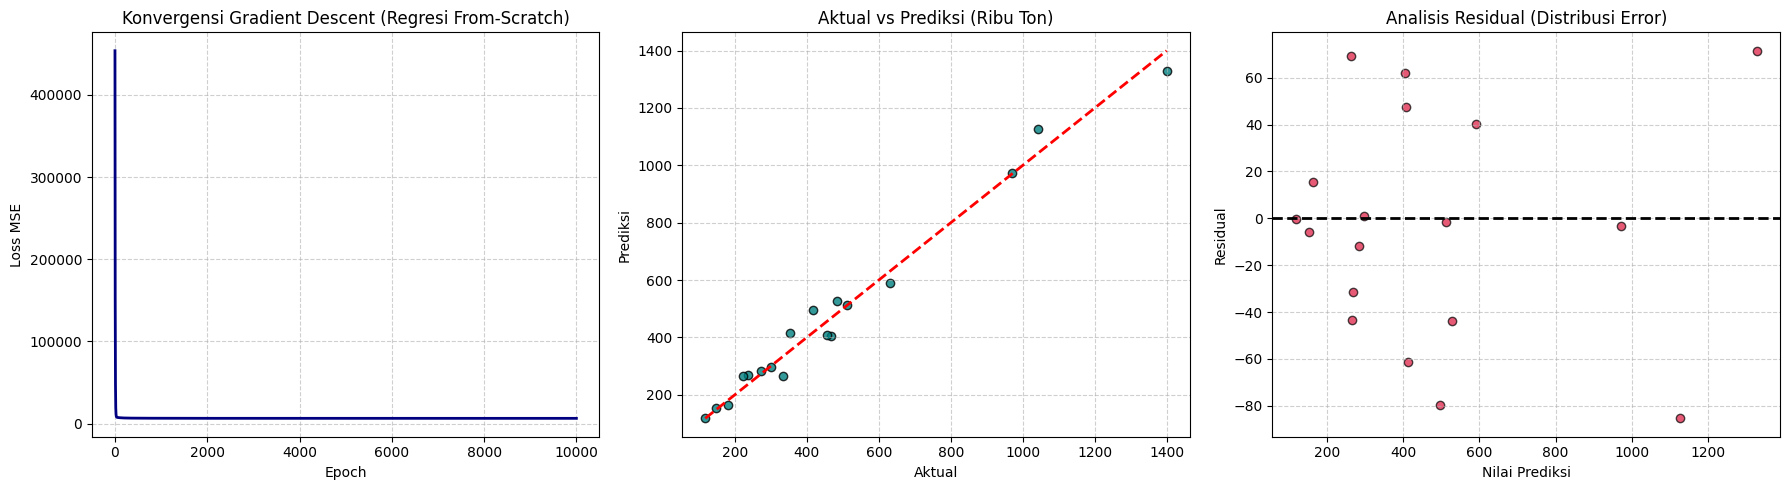

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Konvergensi
axes[0].plot(final_model.loss_history, color='navy', linewidth=2)
axes[0].set_title('Konvergensi Gradient Descent (Regresi From-Scratch)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss MSE')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Aktual vs Prediksi
axes[1].scatter(y_pengujian_np, y_pred_pengujian, color='teal', alpha=0.8, edgecolors='k')
axes[1].plot([y_pengujian_np.min(), y_pengujian_np.max()], [y_pengujian_np.min(), y_pengujian_np.max()], 'r--', lw=2)
axes[1].set_title('Aktual vs Prediksi (Ribu Ton)')
axes[1].set_xlabel('Aktual'); axes[1].set_ylabel('Prediksi')
axes[1].grid(True, linestyle='--', alpha=0.6)

# Plot 3: Error Residual
axes[2].scatter(y_pred_pengujian, residuals, color='crimson', alpha=0.7, edgecolors='k')
axes[2].axhline(y=0, color='black', linestyle='--', lw=2)
axes[2].set_title('Analisis Residual (Distribusi Error)')
axes[2].set_xlabel('Nilai Prediksi'); axes[2].set_ylabel('Residual')
axes[2].grid(True, linestyle='--', alpha=0.6)

print("\n< Berikut adalah Hasil Visualisasi Data >\n")
plt.tight_layout()
plt.show()

## 6. Pengujian Skenario Dunia Nyata (Demonstrasi SDG 13)

### Subtugas:
Mensimulasikan produksi padi masa depan berdasarkan skenario anomali iklim ekstrem dan perubahan luas panen untuk menunjukkan bagaimana model dapat dipakai sebagai alat bantu analisis dalam konteks Aksi Iklim (SDG 13).


In [ ]:
df_pengujian_results = pd.DataFrame({
    'Tahun': df_model.loc[pengujian_mask, 'Tahun'].reset_index(drop=True),
    'Aktual_Ribu_Ton': np.round(y_pengujian_np, 2),
    'Prediksi_Ribu_Ton': np.round(y_pred_pengujian, 2),
    'Residual': np.round(residuals, 2),
    'Absolute_Error': np.round(np.abs(residuals), 2)
}).sort_values(['Tahun', 'Absolute_Error'], ascending=[True, False]).reset_index(drop=True)

print("< SAMPEL DIAGNOSTIK DATA TEST >")
display(df_pengujian_results.head(10))

print(f"Rata-rata Aktual          : {df_pengujian_results['Aktual_Ribu_Ton'].mean():.2f}")
print(f"Rata-rata Prediksi        : {df_pengujian_results['Prediksi_Ribu_Ton'].mean():.2f}")
print(f"Rata-rata Absolute Error  : {df_pengujian_results['Absolute_Error'].mean():.2f}")
print(f"Absolute Error Maksimum   : {df_pengujian_results['Absolute_Error'].max():.2f}")


< SAMPEL DIAGNOSTIK DATA TEST >


,Tahun,Aktual_Ribu_Ton,Prediksi_Ribu_Ton,Residual,Absolute_Error
0,2024,1041.53,1126.87,-85.34,85.34
1,2024,416.48,496.18,-79.71,79.71
2,2024,1399.35,1327.87,71.48,71.48
3,2024,334.19,264.81,69.38,69.38
4,2024,466.84,404.74,62.10,62.10
5,2024,353.42,414.55,-61.14,61.14
6,2024,454.94,407.62,47.32,47.32
7,2024,484.09,527.83,-43.75,43.75
8,2024,223.43,266.66,-43.24,43.24
9,2024,630.85,590.77,40.08,40.08


Rata-rata Aktual          : 474.44
Rata-rata Prediksi        : 477.80
Rata-rata Absolute Error  : 37.48
Absolute Error Maksimum   : 85.34


In [ ]:
print("   < SDG 13 SCENARIO SIMULATION (2026) >")
print("Menguji respons model terhadap berbagai anomali iklim ekstrem:\n")

available_kab = df_full['Kabupaten'].dropna().unique().tolist()
kab_skenario = [kab for kab in ['Indramayu', 'Karawang', 'Subang', 'Cirebon'] if kab in available_kab][:3]
if len(kab_skenario) < 3:
    kab_skenario = available_kab[:3]

# Matriks 3 Skenario beserta label Kabupaten Asli untuk acuan baseline
skenario_data = {
    'Nama_Skenario': [
        f"Skenario 1: El Nino Parah (Kekeringan Ekstrem) di {kab_skenario[0]}",
        f"Skenario 2: La Nina Kuat (Banjir Bandang) di {kab_skenario[1]}",
        f"Skenario 3: Kondisi Menguntungkan & Ekspansi Lahan di {kab_skenario[2]}"
    ],
    'Kabupaten_Asli': kab_skenario,
    'Curah_Hujan_mm': [800.0, 3500.0, 2800.0],
    'Suhu_Rata_C': [29.5, 26.5, 27.5],
    'Luas_Panen_Ha': [190000.0, 150000.0, 240000.0],
    'Kabupaten': kab_skenario
}

df_skenario = pd.DataFrame(skenario_data)
kab_categories = sorted(df_full['Kabupaten'].dropna().unique().tolist())

# Data input untuk model dibentuk dinamis dengan kategori kabupaten yang sama seperti data pelatihan
X_skenario = df_skenario[['Curah_Hujan_mm', 'Suhu_Rata_C', 'Luas_Panen_Ha', 'Kabupaten']].copy()
X_skenario['Kabupaten'] = pd.Categorical(X_skenario['Kabupaten'], categories=kab_categories)
X_skenario = pd.get_dummies(X_skenario, columns=['Kabupaten'], drop_first=True)
X_skenario = X_skenario.reindex(columns=feature_cols, fill_value=False)
X_skenario[num_cols] = X_skenario[num_cols].astype(float)

# Normalisasi menggunakan parameter final train+validation.
X_skenario.loc[:, num_cols] = (X_skenario[num_cols] - X_mean_final) / X_std_final

# Eksekusi prediksi sekaligus
prediksi_skenario = final_model.predict(X_skenario)

threshold_percentage = 0.05

for i in range(len(df_skenario)):
    prediksi = prediksi_skenario[i]
    kab_terpilih = df_skenario['Kabupaten_Asli'][i]

    baseline_production = df_full[df_full['Kabupaten'] == kab_terpilih]['Produksi'].mean() / 1000
    threshold_value = threshold_percentage * baseline_production

    if prediksi < baseline_production - threshold_value:
        status_phrase = "anjlok ke"
    elif prediksi > baseline_production + threshold_value:
        status_phrase = "naik tajam ke"
    else:
        status_phrase = "stabil di"

    print(f"🔸 {df_skenario['Nama_Skenario'][i]}")
    print(f"   • Hujan Lahan : {df_skenario['Curah_Hujan_mm'][i]} mm")
    print(f"   • Suhu Rata2  : {df_skenario['Suhu_Rata_C'][i]} °C")
    print(f"   • Luas Panen  : {df_skenario['Luas_Panen_Ha'][i]:,.0f} Hektar")
    print(f"   => PREDIKSI PRODUKSI : Produksi {status_phrase} level {prediksi:.2f} Ribu Ton")
    print(f"      (Catatan: Rata-rata historis {kab_terpilih} adalah {baseline_production:.2f} Ribu Ton)\n")


   < SDG 13 SCENARIO SIMULATION (2026) >
Menguji respons model terhadap berbagai anomali iklim ekstrem:

🔸 Skenario 1: El Nino Parah (Kekeringan Ekstrem) di Indramayu
   • Hujan Lahan : 800.0 mm
   • Suhu Rata2  : 29.5 °C
   • Luas Panen  : 190,000 Hektar
   => PREDIKSI PRODUKSI : Produksi anjlok ke level 1183.94 Ribu Ton
      (Catatan: Rata-rata historis Indramayu adalah 1386.41 Ribu Ton)

🔸 Skenario 2: La Nina Kuat (Banjir Bandang) di Karawang
   • Hujan Lahan : 3500.0 mm
   • Suhu Rata2  : 26.5 °C
   • Luas Panen  : 150,000 Hektar
   => PREDIKSI PRODUKSI : Produksi anjlok ke level 998.63 Ribu Ton
      (Catatan: Rata-rata historis Karawang adalah 1138.12 Ribu Ton)

🔸 Skenario 3: Kondisi Menguntungkan & Ekspansi Lahan di Subang
   • Hujan Lahan : 2800.0 mm
   • Suhu Rata2  : 27.5 °C
   • Luas Panen  : 240,000 Hektar
   => PREDIKSI PRODUKSI : Produksi naik tajam ke level 1355.90 Ribu Ton
      (Catatan: Rata-rata historis Subang adalah 1020.90 Ribu Ton)



## Tugas Akhir: Ringkasan dan Wawasan

### Temuan Utama dan Analisis Implementasi
1. **Alur regresi dari nol yang lengkap:** Notebook ini mengimplementasikan split kronologis, standardisasi Z-Score manual, optimasi Gradient Descent, perhitungan metrik manual, dan regularisasi L2 opsional tanpa menggunakan scikit-learn atau library machine learning lain.
2. **Dataset lebih kuat dan mudah direproduksi:** Tabel pemodelan final berisi **215 baris cocok** dari **18 kabupaten** untuk periode **2013-2024**, menggunakan ekspor CSV resmi lokal untuk produksi dan luas panen, serta cache iklim Open-Meteo yang sudah dibundel secara lokal. Satu record masih hilang karena data produksi Pangandaran tahun 2013 tidak tersedia pada sumber resmi lokal.
3. **Evaluasi kronologis kini lebih kuat secara metodologis:** Data dibagi menjadi **161 baris pelatihan (2013-2021)**, **36 baris validasi (2022-2023)**, dan **18 baris pengujian (2024)**. Grid search memilih **lambda = 0.0**, sehingga model final harus dilaporkan secara jujur sebagai **Regresi Linear Berganda**, bukan Ridge aktif.
4. **Performa akhir model:** Pada data pengujian tahun 2024 yang benar-benar belum terlihat, model memperoleh **MSE = 2233.67**, **RMSE = 47.26**, **MAE = 37.46**, dan **R² = 0.9799**. Hasil ini menunjukkan kecocokan prediksi yang kuat untuk dataset tahunan tingkat kabupaten yang dipakai, meskipun model ini tetap lebih tepat diposisikan sebagai prototipe analisis pendukung keputusan daripada sistem prediksi produksi yang siap dipakai operasional.
5. **Keterbatasan dan pengembangan lanjutan:** Model saat ini hanya memakai tiga prediktor utama dan agregasi tahunan, sehingga belum menangkap waktu tanam, kualitas irigasi, hama, atau pengaruh pasar. Pengembangan yang masuk akal berikutnya adalah validasi rolling-window, penambahan indikator iklim, atau variabel pertanian yang lebih kaya di tingkat wilayah.
